# Validation: the Laliwala, Amusat & Torres (2025) examples, and how we know the answers are right

**What you will learn.** How to rebuild published equilibrium problems from database data, and how to check any `discopt.speciation` result yourself instead of trusting the solver. The checks are: independent residuals, a PHREEQC comparison, alternative algorithms, invariance tests and a Gibbs-energy test.

**Before you start.** Read [`01-getting-started.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/01-getting-started.ipynb) first. It introduces activities, the saturation index $\mathrm{SI}_k=\log_{10}(Q_k/K_k)$, the Davies equation and complementarity (a candidate solid is either present with $\mathrm{SI}_k=0$, or absent with $\mathrm{SI}_k\le 0$). The equations are summarized in [`docs/concepts.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/concepts.md). Amounts are in mol per kg of water (mol/kgw), and $I=\tfrac12\sum_i z_i^2 m_i$ is the ionic strength. Running the notebook takes about a minute, mostly for the exhaustive enumeration of Case 3. Log lines starting with `INFO pounce...` come from the underlying NLP solver and can be ignored.

Laliwala, Amusat & Torres (2025, [doi:10.69997/sct.132742](https://doi.org/10.69997/sct.132742)) compute aqueous equilibrium with precipitation by minimizing $z=\sum_k \mathrm{SI}_k^2$ over reaction extents. They validate the method on three cases against PHREEQC (Parkhurst & Appelo 2013, [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)). That objective leaves out complementarity: an absent solid does not need $\mathrm{SI}=0$, only $\mathrm{SI}\le 0$. So minimizing $z$ can return states that are not at equilibrium. Its answers can also change when a reaction is rescaled or an inert candidate phase is added. A separate analysis, which is not part of this repository, built small counterexamples for these failures. We re-solve them below (E4).

The notebook collects five independent kinds of evidence that the results are correct equilibria:

1. **E1: Direct verification.** The equilibrium conditions are re-checked from the declared reactions and the returned molalities, with none of the solver's internals. Element totals come from the database formulas; activity coefficients are recomputed from scratch.
2. **E2: An independent code.** Results are compared with PHREEQC 3 on the same minteq.v4 data for every case.
3. **E3: Independent algorithms.** Complementarity homotopy, convex Gibbs minimization, and exhaustive active-set enumeration are run and compared.
4. **E4: Thermodynamic invariances.** Adding a less stable polymorph (another crystal form of the same compound), adding an inert phase, or rescaling a reaction must not change the state. These are counterexamples where the SI² objective fails.
5. **E5: The second law.** Every feasible perturbation of the reaction extents away from the computed state raises $G$.

**Data.** [`data/minteq_cases.json`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/data/minteq_cases.json) holds, for each case, the minteq.v4 log K values and formulas and the PHREEQC results. [`data/notebook_reference.json`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/data/notebook_reference.json) holds independent Pyomo/IPOPT active-set solutions for Case 2 and the counterexamples. Their provenance is recorded in [`tests/data/README.md`](https://github.com/jkitchin/discopt-speciation/blob/main/tests/data/README.md).

In [1]:
import json
import pathlib
import time

import numpy as np
import matplotlib.pyplot as plt

from discopt.speciation import System

DATA = pathlib.Path("data")
CASES = json.loads((DATA / "minteq_cases.json").read_text())
REF = json.loads((DATA / "notebook_reference.json").read_text())
LN10 = np.log(10.0)

## Building the paper's systems from database data

**Goal.** Turn each case in [`data/minteq_cases.json`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/data/minteq_cases.json) into a `System`.

The constants come from [`minteq.v4.dat`](https://github.com/usgs-coupled/phreeqc3/blob/master/database/minteq.v4.dat) as distributed with PHREEQC, which derives from MINTEQA2 (Allison et al. 1991, [OSTI 5673069](https://www.osti.gov/biblio/5673069)). Each case lists:

- **primary species** (the building blocks, e.g. Ag⁺, Cl⁻);
- **secondary aqueous species**, each with a formation reaction from primaries and its $\log_{10}K$ (e.g. Ag⁺ + Cl⁻ = AgCl);
- **candidate solids**, each with a dissolution reaction (solid → ions) and $\log_{10}K$.

`System.reaction` takes a coefficient dict with products positive and reactants negative; `logK` refers to the reaction as written. pH is held fixed as in the paper (a "pH-stat"). The acid or base PHREEQC added to hold it is already included in the totals, which is why Na⁺ or NO₃⁻ are not round numbers. Two more helpers:

- `composition` returns each species' formula in terms of primaries. The independent checker below uses it.
- `solve_case` builds and solves a case and times it.

In [2]:
def minteq_system(case, name="minteq"):
    s = System(name)
    prim = case["primaries"]
    for p in prim:
        s.aqueous(p, case["species"][p]["z"])
    for sp, d in case["species"].items():
        if sp in prim or not d["nu"]:          # skip primaries and H2O
            continue
        s.aqueous(sp, d["z"])
        s.reaction({**{k: -v for k, v in d["nu"].items()}, sp: 1.0}, logK=d["logK"])
    for ph, d in case["phases"].items():
        s.solid(ph)
        s.reaction({ph: -1.0, **d["nu"]}, logK=d["logK"])
    return s


def composition(case):
    """Formula of every species/phase in terms of primaries (the chemistry, not the solver's matrix)."""
    comp = {sp: d["nu"] for sp, d in case["species"].items()}
    comp.update({ph: d["nu"] for ph, d in case["phases"].items()})
    return comp


def solve_case(name, activity="ideal", method="complementarity"):
    case = CASES[name]
    s = minteq_system(case, name)
    t0 = time.perf_counter()
    res = s.equilibrate(case["totals"], pH=case["pH"], activity=activity, method=method)
    return s, res, time.perf_counter() - t0


s1 = minteq_system(CASES["Case 1"], "Case 1")
print(s1)
for r in s1.reactions:
    print(f"  {r.equation():40s} logK = {r.logK:+.3f}")

System('Case 1', 12 aqueous, 2 solid, 10 reactions)
  0 = H+ + OH-                             logK = -13.997
  Ag+ = H+ + AgOH                          logK = -11.997
  Ag+ = 2 H+ + Ag(OH)2-                    logK = -24.004
  Ag+ + Cl- = AgCl                         logK = +3.310
  Ag+ + 2 Cl- = AgCl2-                     logK = +5.250
  Ag+ + 3 Cl- = AgCl3-2                    logK = +5.200
  Ag+ + 4 Cl- = AgCl4-3                    logK = +5.510
  Ag+ + NO3- = AgNO3                       logK = -0.100
  Ag2O + 2 H+ = 2 Ag+                      logK = +12.574
  Cerargyrite = Ag+ + Cl-                  logK = -9.750


**Output.** Case 1 has 12 aqueous species, 2 candidate solids and 10 reactions. Each line is printed as reactants = products. Two lines need explaining:

- `0 = H+ + OH-` is water dissociation, with H₂O omitted (its activity is 1), and $\log K = -14.0$.
- The Ag₂O line is written with H⁺ on the left: Ag₂O + 2 H⁺ = 2 Ag⁺. Its $\log K$ belongs to that direction.

## E1: An independent checker

**Goal.** Solver residuals only show that the solver met its own equations. `verify` instead recomputes the equilibrium conditions from scratch. It uses only the declared reactions, the input amounts and the returned molalities and solid amounts. It checks:

- **conservation.** For database cases, every element total is computed from the species formulas. For hand-written systems it uses the left null space of the stoichiometric matrix, found by SVD. The package itself uses exact rational row reduction.
- **mass action.** $\log_{10}Q - \log_{10}K$ for every aqueous reaction. Activity coefficients are recomputed here from the molalities and charges, for both ideal and Davies.
- **complementarity.** Every $n_k \ge 0$, every $\mathrm{SI}_k \le 0$, and $\min(n_k/n_{\rm scale}, -\mathrm{SI}_k) = 0$.

Each number is a maximum over all species or reactions, so a value near zero (about 1e-8 or less) is a pass. `n_scale` is the largest input amount, which makes solid amounts dimensionless. The function also reports the paper's objective $z=\sum_k (\log_{10}Q_k-\log_{10}K_k)^2$, taken over the solid reactions *as written*. This equals $\sum_k\mathrm{SI}_k^2$ only when each reaction dissolves one formula unit (see E4).

`show_checks` prints one line of these numbers. `compare_phreeqc` prints our solid amounts and SI next to PHREEQC's.

In [3]:
# Davies equation: log10(gamma) = -A z^2 (sqrt(I)/(1+sqrt(I)) - b I).
# Use the same Debye-Hueckel A(25 C) as the package (0.5100; 0.509 is an older textbook value).
from discopt.speciation.water import debye_huckel_A
A_DAVIES, B_DAVIES = debye_huckel_A(298.15), 0.3


def verify(system, res, amounts, pH=None, activity="ideal", composition=None):
    """Recheck conservation, mass action and complementarity from the reaction data and returned amounts only."""
    fixed = {"H+": -pH} if pH is not None else {}
    names = [sp.name for sp in system.species if sp.name not in fixed]
    amount = lambda n: res.molality[n] if n in res.molality else res.solids[n]
    state = np.array([amount(n) for n in names])
    init = np.array([float(amounts.get(n, 0.0)) for n in names])

    # -- conservation
    if composition is not None:
        comps = sorted({c for n in names for c in composition[n] if c not in fixed})
        B = np.array([[composition[n].get(c, 0.0) for n in names] for c in comps])
    else:
        N = np.array([[r.stoich.get(system[n], 0.0) for r in system.reactions] for n in names])
        U, sv, _ = np.linalg.svd(N)
        B = U[:, int((sv > 1e-9).sum()):].T
    balance = np.max(np.abs(B @ (state - init)) / np.maximum(np.abs(B) @ init, 1e-300))

    # -- activities recomputed from molalities
    z = {sp.name: sp.charge for sp in system.species}
    I = 0.5 * sum(z[n] ** 2 * m for n, m in res.molality.items())
    def log10_gamma(n):
        if activity == "ideal" or z[n] == 0:
            return 0.0
        sI = np.sqrt(I)
        return -A_DAVIES * z[n] ** 2 * (sI / (1 + sI) - B_DAVIES * I)
    def log10_a(n):
        if n in fixed:
            return fixed[n]
        if system[n].is_solid:
            return 0.0
        return np.log10(res.molality[n]) + log10_gamma(n)

    # -- mass action and saturation
    mass_action, SI, z_paper = [], {}, 0.0
    for r in system.reactions:
        dev = sum(c * log10_a(sp.name) for sp, c in r.stoich.items()) - r.logK
        solid = [sp for sp in r.stoich if sp.is_solid]
        if solid:
            SI[solid[0].name] = dev / (-r.stoich[solid[0]])
            z_paper += dev ** 2
        else:
            mass_action.append(abs(dev))
    n = {k: res.solids[k] for k in SI}
    scale = max(init.max(), max(n.values(), default=0.0))
    return {
        "I": I,
        "balance": balance,
        "mass_action": max(mass_action, default=0.0),
        "max_SI": max(SI.values(), default=-np.inf),
        "min_solid": min(n.values(), default=0.0),
        "complementarity": max((abs(min(n[k] / scale, -SI[k])) for k in SI), default=0.0),
        "z_paper": z_paper,
        "SI": SI,
    }


def show_checks(label, c):
    print(f"{label:28s} balance {c['balance']:.1e} | mass action {c['mass_action']:.1e} | "
          f"max SI {c['max_SI']:+.1e} | min solid {c['min_solid']:+.1e} | complementarity {c['complementarity']:.1e}")


def compare_phreeqc(name, res, activity):
    ref = CASES[name]["phreeqc_ideal" if activity == "ideal" else "phreeqc_activity"]
    print(f"{'phase':<18}{'discopt.speciation':>16}{'PHREEQC':>14}{'SI (ours)':>12}{'SI (PHREEQC)':>14}")
    for ph, nref in ref["n"].items():
        print(f"{ph:<18}{res.solids[ph]:>16.6e}{nref:>14.6e}{res.SI[ph]:>12.4f}{ref['SI'][ph]:>14.4f}")

## Case 1: Silver chloride at pH 5

**Setup.** Ag⁺, Cl⁻ and NO₃⁻ are each 10⁻⁴ mol/kgw. The candidate solids are the Ag/Cl/N solids in the database: cerargyrite (AgCl) and Ag₂O. **Expected.** Cerargyrite precipitates, and Ag₂O stays far undersaturated at pH 5.

The cell solves the case twice, with ideal activities and with Davies activities (Davies 1938, [doi:10.1039/JR9380002093](https://doi.org/10.1039/JR9380002093)). Each run is compared with PHREEQC and then passed to the independent checker.

In [4]:
checks = {}
for activity in ["ideal", "davies"]:
    s, res, dt = solve_case("Case 1", activity)
    print(f"--- {activity} ({dt:.2f} s), converged = {res.converged}, I = {res.ionic_strength:.3e}")
    compare_phreeqc("Case 1", res, activity)
    case = CASES["Case 1"]
    c = verify(s, res, case["totals"], case["pH"], activity, composition(case))
    checks[("Case 1", activity)] = (res, c)
    show_checks("independent check", c)

--- ideal (0.16 s), converged = True, I = 6.834e-05
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ag2O                  0.000000e+00  0.000000e+00    -12.3240      -12.3240
Cerargyrite           8.630054e-05  8.630054e-05     -0.0000        0.0000
independent check            balance 1.6e-16 | mass action 1.8e-15 | max SI +0.0e+00 | min solid +0.0e+00 | complementarity 0.0e+00


--- davies (0.04 s), converged = True, I = 6.851e-05
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ag2O                  0.000000e+00  0.000000e+00    -12.3240      -12.3240
Cerargyrite           8.617169e-05  8.617170e-05     -0.0000        0.0000
independent check            balance 2.9e-12 | mass action 3.6e-15 | max SI +0.0e+00 | min solid +0.0e+00 | complementarity 0.0e+00


**Result.** 8.63 × 10⁻⁵ mol/kgw of cerargyrite precipitates, about 86% of the silver. Ag₂O has SI = −12.3. Solid amounts and SI match PHREEQC to the printed digits (ideal) or to 1 part in 10⁷ (Davies). The ionic strength is tiny ($I\approx 7\times10^{-5}$), so the activity model barely matters here. The checker line shows conservation and mass action near machine precision, no negative solids and no supersaturation.

## Case 2: Gypsum in a multicomponent brine

**Setup.** The paper's Table 1 brine (Na, K, Ca, Mg, Cl, SO₄) at pH 7, with gypsum (CaSO₄·2H₂O) as the only candidate solid. **Why it is interesting.** The ionic strength is about 0.03–0.05 mol/kgw, so activity corrections matter. Ideal activities overestimate how much gypsum precipitates.

PHREEQC's activity model uses the WATEQ Debye–Hückel form (Truesdell & Jones 1974, [USGS](https://pubs.usgs.gov/publication/70232379)) for ions with size parameters and Davies for the rest. A difference well under 1% from our pure Davies model is therefore expected.

We also compare with a second, independent reference: an active-set solution computed with Pyomo/IPOPT, stored in [`data/notebook_reference.json`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/data/notebook_reference.json). The analysis that produced it is not part of this repository.

In [5]:
for activity in ["ideal", "davies"]:
    s, res, dt = solve_case("Case 2", activity)
    print(f"--- {activity} ({dt:.2f} s), converged = {res.converged}, I = {res.ionic_strength:.4f}")
    compare_phreeqc("Case 2", res, activity)
    case = CASES["Case 2"]
    c = verify(s, res, case["totals"], case["pH"], activity, composition(case))
    checks[("Case 2", activity)] = (res, c)
    show_checks("independent check", c)

ref = REF["Case2_davies"]
res = checks[("Case 2", "davies")][0]
print(f"\nDavies vs Pyomo reference: gypsum {res['Gypsum']:.6e} vs {ref['gypsum']:.6e}, "
      f"I {res.ionic_strength:.6f} vs {ref['I']:.6f}")

--- ideal (0.02 s), converged = True, I = 0.0255
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Gypsum                1.685327e-02  1.685411e-02     -0.0000        0.0000
independent check            balance 3.3e-16 | mass action 1.8e-15 | max SI +0.0e+00 | min solid +1.7e-02 | complementarity 0.0e+00
--- davies (0.03 s), converged = True, I = 0.0458
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Gypsum                1.179122e-02  1.178531e-02     -0.0000        0.0000
independent check            balance 4.6e-16 | mass action 1.8e-15 | max SI -8.9e-16 | min solid +1.2e-02 | complementarity 8.9e-16

Davies vs Pyomo reference: gypsum 1.179122e-02 vs 1.181127e-02, I 0.045781 vs 0.045700


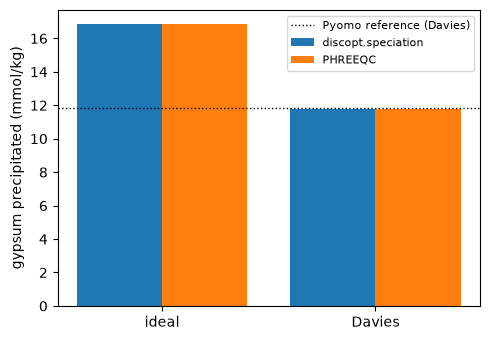

In [6]:
labels = ["ideal", "Davies"]
ours = [checks[("Case 2", a)][0]["Gypsum"] for a in ["ideal", "davies"]]
phq = [CASES["Case 2"]["phreeqc_ideal"]["n"]["Gypsum"], CASES["Case 2"]["phreeqc_activity"]["n"]["Gypsum"]]
x = np.arange(2)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(x - 0.2, np.array(ours) * 1e3, 0.4, label="discopt.speciation")
ax.bar(x + 0.2, np.array(phq) * 1e3, 0.4, label="PHREEQC")
ax.axhline(REF["Case2_davies"]["gypsum"] * 1e3, color="k", ls=":", lw=1, label="Pyomo reference (Davies)")
ax.set_xticks(x, labels)
ax.set_ylabel("gypsum precipitated (mmol/kg)")
ax.legend(fontsize=8)
plt.tight_layout()

**Result.** Gypsum precipitated is 16.85 mmol/kg with ideal activities and 11.79 mmol/kg with Davies, so the ideal model overpredicts by about 43%. In the bar chart the two codes are indistinguishable. The PHREEQC differences are 0.005% (ideal) and 0.05% (activity-corrected). The Pyomo reference is 11.81 mmol/kg ($I$ = 0.04570 versus our 0.04578). The 0.2% gap comes from the Davies constant alone: the reference used the textbook $A=0.509$, and re-solving here with `activity={"model": "davies", "A": 0.509}` reproduces it (11.811 mmol/kg, $I$ = 0.045700).

## Case 3: Trace iron with seven candidate precipitates

**Setup.** Case 2's brine plus 10⁻⁶ mol/kgw Fe(III), with seven candidate phases: six iron phases and gypsum. It is solved at pH 7 and again at pH 7.5. **Expected.** Gypsum still precipitates. The iron goes into the most stable Fe phase, hematite (Fe₂O₃), and every other Fe phase stays undersaturated.

This case separates a correct solver from the SI² objective most sharply. That objective can push several Fe phases towards saturation at the same time, although only one of them can coexist with the fixed iron total.

The bar charts show the ideal-activity SI of each phase. The black ticks are PHREEQC's values. The two phases that are present have SI = 0, so their bars have zero length.

 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=2.9996007097620927e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1


--- Case 3, ideal (4.12 s), converged = True, present = ['Hematite', 'Gypsum']
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ferrihydrite          0.000000e+00  0.000000e+00     -3.9000       -3.9002
Goethite              0.000000e+00  0.000000e+00     -1.2000       -1.2001
Hematite              4.999997e-07  4.999997e-07      0.0000        0.0000
Magnesioferrite       0.000000e+00  0.000000e+00     -8.3492       -8.3491
Fe(OH)2.7Cl.3         0.000000e+00  0.000000e+00     -0.8123       -0.8124
K-Jarosite            0.000000e+00  0.000000e+00    -16.9361      -16.9359
Gypsum                1.685326e-02  1.685410e-02     -0.0000        0.0000
independent check            balance 1.4e-15 | mass action 3.6e-15 | max SI +6.7e-16 | min solid +0.0e+00 | complementarity 6.7e-16


 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=1.5000615486464205e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1
 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=1.5000615486464205e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1
 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=1.5000615486464205e-7 obj=

--- Case 3, davies (3.92 s), converged = True, present = ['Hematite', 'Gypsum']
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ferrihydrite          0.000000e+00  0.000000e+00     -3.9000       -3.9003
Goethite              0.000000e+00  0.000000e+00     -1.2000       -1.2001
Hematite              4.999997e-07  4.999997e-07      0.0000        0.0000
Magnesioferrite       0.000000e+00  0.000000e+00     -8.6327       -8.6328
Fe(OH)2.7Cl.3         0.000000e+00  0.000000e+00     -0.8371       -0.8373
K-Jarosite            0.000000e+00  0.000000e+00    -16.7171      -16.7166
Gypsum                1.179117e-02  1.178526e-02     -0.0000        0.0000
independent check            balance 1.3e-15 | mass action 3.6e-15 | max SI +6.7e-16 | min solid +0.0e+00 | complementarity 6.7e-16


--- Case 3 (pH 7.5), ideal (0.33 s), converged = True, present = ['Hematite', 'Gypsum']
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ferrihydrite          0.000000e+00  0.000000e+00     -3.9000       -3.9002
Goethite              0.000000e+00  0.000000e+00     -1.2000       -1.2001
Hematite              4.999999e-07  4.999999e-07      0.0000       -0.0000
Magnesioferrite       0.000000e+00  0.000000e+00     -7.3492       -7.3491
Fe(OH)2.7Cl.3         0.000000e+00  0.000000e+00     -0.9623       -0.9624
K-Jarosite            0.000000e+00  0.000000e+00    -18.4361      -18.4359
Gypsum                1.685327e-02  1.685411e-02     -0.0000        0.0000
independent check            balance 6.6e-16 | mass action 3.6e-15 | max SI +6.7e-16 | min solid +0.0e+00 | complementarity 6.7e-16


--- Case 3 (pH 7.5), davies (3.62 s), converged = True, present = ['Hematite', 'Gypsum']
phase             discopt.speciation       PHREEQC   SI (ours)  SI (PHREEQC)
Ferrihydrite          0.000000e+00  0.000000e+00     -3.9000       -3.9003
Goethite              0.000000e+00  0.000000e+00     -1.2000       -1.2001
Hematite              4.999999e-07  4.999999e-07      0.0000       -0.0000
Magnesioferrite       0.000000e+00  0.000000e+00     -7.6327       -7.6328
Fe(OH)2.7Cl.3         0.000000e+00  0.000000e+00     -0.9871       -0.9873
K-Jarosite            0.000000e+00  0.000000e+00    -18.2171      -18.2166
Gypsum                1.179119e-02  1.178527e-02     -0.0000        0.0000
independent check            balance 4.1e-16 | mass action 3.6e-15 | max SI +6.7e-16 | min solid +0.0e+00 | complementarity 8.9e-16


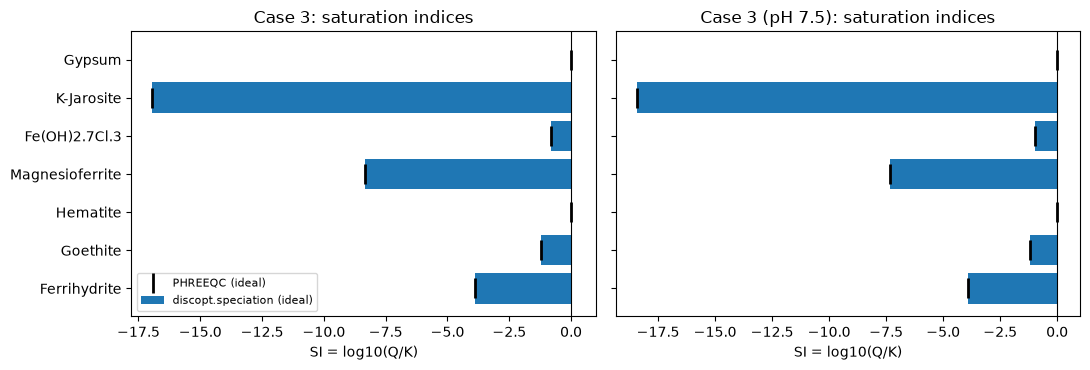

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, name in zip(axes, ["Case 3", "Case 3 (pH 7.5)"]):
    for activity in ["ideal", "davies"]:
        s, res, dt = solve_case(name, activity)
        print(f"--- {name}, {activity} ({dt:.2f} s), converged = {res.converged}, present = {res.present}")
        compare_phreeqc(name, res, activity)
        case = CASES[name]
        c = verify(s, res, case["totals"], case["pH"], activity, composition(case))
        checks[(name, activity)] = (res, c)
        show_checks("independent check", c)
    res = checks[(name, "ideal")][0]
    phases = list(res.SI)
    ax.barh(phases, [res.SI[p] for p in phases], color=["C2" if p in res.present else "C0" for p in phases], label="discopt.speciation (ideal)")
    ax.plot([CASES[name]["phreeqc_ideal"]["SI"][p] for p in phases], phases, "k|", ms=14, mew=2, label="PHREEQC (ideal)")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_xlim(right=1.0)
    ax.set(title=f"{name}: saturation indices", xlabel="SI = log10(Q/K)")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()

**Result.** At both pH values the assemblage is hematite + gypsum, in both codes. Hematite is 5.0 × 10⁻⁷ mol/kgw, i.e. all 10⁻⁶ mol of Fe as Fe₂O₃. Gypsum is unchanged from Case 2. The closest competitors are Fe(OH)₂.₇Cl₀.₃ (SI ≈ −0.8) and goethite (SI = −1.2).

Raising pH to 7.5 shifts only the phases whose dissolution reactions release a different number of H⁺ than hematite does: magnesioferrite rises by 1.0 and K-jarosite falls by 1.5. The goethite and ferrihydrite SI stay the same, because saturated hematite fixes the Fe³⁺ and OH⁻ activity product for them. Every SI agrees with PHREEQC to within 5 × 10⁻⁴.

## E1 + E2 summary

The table collects every run above. Its columns are:

- whether the phase assemblage matches PHREEQC (✓);
- the largest relative difference in solid amount and the largest SI difference from PHREEQC;
- the three independent-checker residuals.

In [8]:
print(f"{'case':<18}{'activity':<9}{'assemblage (ours = PHREEQC)':<30}{'max rel dev n':>14}{'max |dSI|':>11}"
      f"{'balance':>10}{'mass act.':>10}{'compl.':>10}")
for (name, activity), (res, c) in checks.items():
    ref = CASES[name]["phreeqc_ideal" if activity == "ideal" else "phreeqc_activity"]
    same = set(res.present) == {k for k, v in ref["n"].items() if v > 0}
    dev = max(abs(res.solids[k] - v) / v for k, v in ref["n"].items() if v > 0)
    dsi = max(abs(res.SI[k] - v) for k, v in ref["SI"].items())
    print(f"{name:<18}{activity:<9}{(', '.join(res.present) + ('  ✓' if same else '  ✗')):<30}{dev:>14.1e}{dsi:>11.1e}"
          f"{c['balance']:>10.1e}{c['mass_action']:>10.1e}{c['complementarity']:>10.1e}")

case              activity assemblage (ours = PHREEQC)    max rel dev n  max |dSI|   balance mass act.    compl.
Case 1            ideal    Cerargyrite  ✓                       5.5e-10    1.0e-06   1.6e-16   1.8e-15   0.0e+00
Case 1            davies   Cerargyrite  ✓                       1.9e-07    1.0e-06   2.9e-12   3.6e-15   0.0e+00
Case 2            ideal    Gypsum  ✓                            5.0e-05    0.0e+00   3.3e-16   1.8e-15   0.0e+00
Case 2            davies   Gypsum  ✓                            5.0e-04    0.0e+00   4.6e-16   1.8e-15   8.9e-16
Case 3            ideal    Hematite, Gypsum  ✓                  5.0e-05    2.1e-04   1.4e-15   3.6e-15   6.7e-16
Case 3            davies   Hematite, Gypsum  ✓                  5.0e-04    4.4e-04   1.3e-15   3.6e-15   6.7e-16
Case 3 (pH 7.5)   ideal    Hematite, Gypsum  ✓                  5.0e-05    2.1e-04   6.6e-16   3.6e-15   6.7e-16
Case 3 (pH 7.5)   davies   Hematite, Gypsum  ✓                  5.0e-04    4.4e-04   4.1e-16   3

**Result.**
- **Assemblages.** Identical to PHREEQC in all eight runs.
- **Ideal runs.** Solid amounts agree to 5 × 10⁻⁵ relative and SI to 2 × 10⁻⁴. This is the size of PHREEQC's small water-mass and water-activity effects, which are not modeled here.
- **Activity-corrected runs.** Amounts agree to 5 × 10⁻⁴ (0.05%) and SI to 4.4 × 10⁻⁴. This is consistent with Davies versus PHREEQC's mixed Debye–Hückel/Davies model.
- **Independent checker.** Every run passes: the largest balance residual is 3 × 10⁻¹² and the largest mass-action and complementarity residuals are below 10⁻¹⁴, with no supersaturated solid and no negative amount.

## E3: Three algorithms, one answer

**Goal.** Show that the answer does not depend on one algorithm's quirks. `equilibrate(method=...)` offers three methods that find the phase assemblage in different ways:

- `"complementarity"` (default): a smoothed Fischer–Burmeister reformulation of the complementarity conditions, solved by homotopy (Fischer 1992, [doi:10.1080/02331939208843795](https://doi.org/10.1080/02331939208843795); Kanzow 1996, [doi:10.1137/S0895479894273134](https://doi.org/10.1137/S0895479894273134));
- `"gibbs"`: convex minimization of the Gibbs energy, which never looks at saturation indices (Smith & Missen 1982);
- `"enumerate"`: solves every one of the $2^{n_\text{solids}}$ assemblages (128 for Case 3, so it takes 30 s or so) and keeps those that satisfy the equilibrium conditions. If more than one passes the numerical tolerance, it keeps the one with the lowest $G$.

The cell compares each method's molalities and solid amounts with the complementarity result.

In [9]:
for name in ["Case 1", "Case 2", "Case 3"]:
    results = {}
    for method in ["complementarity", "gibbs", "enumerate"]:
        s, res, dt = solve_case(name, "ideal", method)
        results[method] = res
        print(f"{name:8s} {method:16s} converged={res.converged}  present={res.present}  ({dt:5.2f} s)")
    base = results["complementarity"]
    for method in ["gibbs", "enumerate"]:
        r = results[method]
        dm = max(abs(r.molality[k] - v) / v for k, v in base.molality.items() if v > 1e-30)
        dn = max((abs(r.solids[k] - v) / v for k, v in base.solids.items() if v > 0), default=0.0)
        print(f"{'':8s}   {method} vs complementarity: max rel diff molality {dm:.1e}, solids {dn:.1e}")
    notes = [n for n in results["enumerate"].info.notes if "assemblages" in n]
    print(f"{'':8s}   enumeration: {notes[0] if notes else 'exactly one assemblage satisfies the equilibrium conditions'}\n")

Case 1   complementarity  converged=True  present=['Cerargyrite']  ( 0.03 s)
Case 1   gibbs            converged=True  present=['Cerargyrite']  ( 0.01 s)
Case 1   enumerate        converged=True  present=['Cerargyrite']  ( 0.04 s)
           gibbs vs complementarity: max rel diff molality 2.1e-10, solids 3.2e-11
           enumerate vs complementarity: max rel diff molality 0.0e+00, solids 0.0e+00
           enumeration: exactly one assemblage satisfies the equilibrium conditions

Case 2   complementarity  converged=True  present=['Gypsum']  ( 0.02 s)


Case 2   gibbs            converged=True  present=['Gypsum']  ( 0.03 s)
Case 2   enumerate        converged=True  present=['Gypsum']  ( 0.01 s)
           gibbs vs complementarity: max rel diff molality 1.3e-13, solids 2.1e-16
           enumerate vs complementarity: max rel diff molality 4.1e-15, solids 0.0e+00
           enumeration: exactly one assemblage satisfies the equilibrium conditions



 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=2.9996007097620927e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1


Case 3   complementarity  converged=True  present=['Hematite', 'Gypsum']  ( 3.85 s)
Case 3   gibbs            converged=True  present=['Hematite', 'Gypsum']  ( 0.03 s)


 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=2.9996007097620927e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1
 INFO pounce_algorithm::conv_check::opt_error: refusing an acceptable-level termination: the error has been inside the acceptable band for the whole streak but is still moving across it, so the streak has not flattened; continuing (acceptable_progress_kappa=0 disables) nlp_err=2.9996007097620927e-7 obj=0.0 acceptable_tol=1e-6 window=15 kappa=0.1


...

 INFO pounce::linesearch: theta_max raised 1.965e5 -> 1.965e7 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


 INFO pounce::linesearch: theta_max raised 1.965e5 -> 1.965e7 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


 INFO pounce::linesearch: theta_max raised 1.764e5 -> 1.764e7 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)
 INFO pounce::linesearch: theta_max raised 1.764e5 -> 1.764e7 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


 INFO pounce::linesearch: theta_max raised 1.764e5 -> 1.764e7 (raise 1 of 4): 3 consecutive line searches had every trial rejected at the theta_max gate (pounce#546)


Case 3   enumerate        converged=True  present=['Hematite', 'Gypsum']  (32.08 s)
           gibbs vs complementarity: max rel diff molality 8.2e-15, solids 1.7e-15
           enumerate vs complementarity: max rel diff molality 4.0e-15, solids 1.5e-15
           enumeration: 2 assemblages satisfy complementarity; kept lowest G



**Result.** All three methods return the same assemblage in every case. Molalities agree to 2 × 10⁻¹⁰ relative or better, and solid amounts to 3 × 10⁻¹¹ or better. For Cases 1 and 2, enumeration finds exactly one valid assemblage. For Case 3, two assemblages pass the enumeration tolerance, and the lower-Gibbs-energy one is hematite + gypsum, the same answer as the other two methods.

## E4: Invariances (counterexamples to the SI² objective)

**Goal.** Test properties any true equilibrium must have, using tiny systems built to break the SI² objective. M, L, N and X are generic aqueous species, ML is a complex, and NL(s), MX(s) and MX′(s) are solids. A true equilibrium must be unchanged by:

- **CE1:** listing a less stable polymorph (ferrihydrite next to goethite);
- **CE2 → CE3:** adding an inert, undersaturated candidate phase MX′(s);
- **CE2 → CE4:** writing the MX(s) reaction doubled, with doubled log K.

CE2 also tests coupling through a complex: NL(s) precipitation changes the free-ligand concentration, and so the MX(s) saturation. The reference amounts are the independent Pyomo/IPOPT active-set solutions in [`data/notebook_reference.json`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/data/notebook_reference.json).

We also print the paper's objective $z$ evaluated at the true equilibrium. If $z$ were a valid criterion it would be zero there, and the same for all equivalent descriptions of one system.

In [10]:
def ce2_system(extra_solid=False, double_MX=False):
    s = System("CE2")
    M, L, ML, N, X = (s.aqueous(n) for n in ("M", "L", "ML", "N", "X"))
    NL, MX = s.solid("NL(s)"), s.solid("MX(s)")
    s.reaction(M + L >> ML, logK=3.0)
    s.reaction(NL >> N + L, logK=-4.0)
    if double_MX:
        s.reaction(2 * MX >> 2 * M + 2 * X, logK=-12.0)
    else:
        s.reaction(MX >> M + X, logK=-6.0)
    if extra_solid:
        s.reaction(s.solid("MX'(s)") >> M + X, logK=-3.0)
    return s

def ce1_system():
    s = System("CE1")
    Fe, NO3, H, OH = s.aqueous("Fe+3"), s.aqueous("NO3-"), s.aqueous("H+"), s.aqueous("OH-")
    s.reaction({H: 1, OH: 1}, logK=-14.0)
    s.reaction(s.solid("Ferrihydrite") >> Fe + 3 * OH, logK=4.891 - 42.0)
    s.reaction(s.solid("Goethite") >> Fe + 3 * OH, logK=-43.0)
    return s

CE2_IN = {"M": 1e-3, "L": 2e-2, "N": 2e-2, "X": 1e-3}
CE1_IN = {"Fe+3": 1e-3, "NO3-": 3e-3, "H+": 1e-7, "OH-": 1e-7}
systems = {"CE1": (ce1_system(), CE1_IN), "CE2": (ce2_system(), CE2_IN),
           "CE3": (ce2_system(extra_solid=True), CE2_IN), "CE4": (ce2_system(double_MX=True), CE2_IN)}

ce = {}
print(f"{'':5}{'solid':<14}{'discopt.speciation':>16}{'reference':>14}{'SI':>10}   {'z_paper at equilibrium':>22}")
for key, (s, amounts) in systems.items():
    res = s.equilibrate(amounts)
    c = verify(s, res, amounts)
    ce[key] = res
    for i, (k, v) in enumerate(REF[key]["n"].items()):
        label = key if i == 0 else ""
        z_col = f"{c['z_paper']:22.4f}" if i == 0 else ""
        print(f"{label:5}{k:<14}{res.solids[k]:>16.10e}{v:>14.6e}{res.SI[k]:>10.4f}   {z_col}")
    show_checks(f"  {key} independent check", c)

print("\nmax relative change in aqueous state, CE3 vs CE2:", max(abs(ce["CE3"].molality[k] / v - 1) for k, v in ce["CE2"].molality.items()))
print("max relative change in aqueous state, CE4 vs CE2:", max(abs(ce["CE4"].molality[k] / v - 1) for k, v in ce["CE2"].molality.items()))

     solid         discopt.speciation     reference        SI   z_paper at equilibrium
CE1  Ferrihydrite  0.0000000000e+00  0.000000e+00   -5.8910                  34.7039
     Goethite      9.9999730002e-04  9.999973e-04   -0.0000   
  CE1 independent check      balance 4.7e-16 | mass action 0.0e+00 | max SI +0.0e+00 | min solid +0.0e+00 | complementarity 0.0e+00
CE2  NL(s)         9.5371203161e-03  9.537120e-03   -0.0000                   1.0477
     MX(s)         0.0000000000e+00  0.000000e+00   -1.0236   
  CE2 independent check      balance 1.7e-16 | mass action 0.0e+00 | max SI +0.0e+00 | min solid +0.0e+00 | complementarity 0.0e+00
CE3  NL(s)         9.5371203161e-03  9.537120e-03   -0.0000                  17.2368
     MX(s)         0.0000000000e+00  0.000000e+00   -1.0236   
     MX'(s)        0.0000000000e+00  0.000000e+00   -4.0236   
  CE3 independent check      balance 1.1e-16 | mass action 0.0e+00 | max SI +0.0e+00 | min solid +0.0e+00 | complementarity 0.0e+00
CE4  NL(s)

**Result.**
- **CE1.** Goethite precipitates and ferrihydrite stays undersaturated (SI = −5.89).
- **CE2, CE3 and CE4.** They give identical states: NL(s) = 9.537 × 10⁻³ mol/kgw, MX(s) absent with SI = −1.02, and a relative change in the aqueous state of exactly 0. All amounts match the reference. Its CE4 value of 10⁻³³ for MX(s) is zero to solver precision.
- **The objective.** $z$ at this single equilibrium is 1.05 for CE2, 17.24 for CE3 (the inert phase adds its SI²) and 4.19 for CE4 (doubling the reaction doubles its deviation). A method that minimizes $z$ would therefore move away from the equilibrium, by a different amount for each description.

**Scan across a phase boundary.** Next we vary the X input from 10⁻⁴ to 5 × 10⁻² mol/kgw. Lines are `discopt.speciation` on an 80-point grid, and circles are the independent active-set reference.

**Result.** NL(s) is present throughout. MX(s) is zero until X ≈ 10⁻² mol/kgw, then grows. Above that point NL(s) also rises slightly, because MX(s) formation pulls M out of the ML complex and frees L. Every reference point lies on the curves, and no MX(s) appears below the boundary.

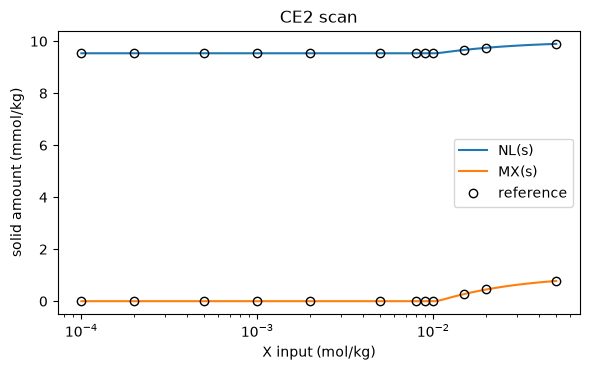

In [11]:
X0 = np.logspace(-4, np.log10(5e-2), 80)
n_NL, n_MX = [], []
s = ce2_system()
for x in X0:
    r = s.equilibrate(dict(CE2_IN, X=x))
    assert r.converged
    n_NL.append(r["NL(s)"])
    n_MX.append(r["MX(s)"])
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.semilogx(X0, np.array(n_NL) * 1e3, label="NL(s)")
ax.semilogx(X0, np.array(n_MX) * 1e3, label="MX(s)")
ax.semilogx([p["X0"] for p in REF["CE2_scan"]], [p["n"]["NL(s)"] * 1e3 for p in REF["CE2_scan"]], "ko", mfc="none", label="reference")
ax.semilogx([p["X0"] for p in REF["CE2_scan"]], [p["n"]["MX(s)"] * 1e3 for p in REF["CE2_scan"]], "ko", mfc="none")
ax.set(xlabel="X input (mol/kg)", ylabel="solid amount (mmol/kg)", title="CE2 scan")
ax.legend()
plt.tight_layout()

## E5: The computed state minimizes the Gibbs energy

**Goal.** Check the second law directly. At constant $T$, $P$ and composition, equilibrium is the global minimum of $G$ over all states reachable by the reactions (Smith & Missen 1982). For ideal activities,

$$\frac{G}{RT} = \sum_{i\in\text{aq}} m_i\left(\mu^\circ_i + \ln m_i - 1\right) + \sum_{k\in\text{solids}} n_k \mu^\circ_k,\qquad \sum_i \nu_{ij}\,\mu^\circ_i = -\ln(10)\log_{10} K_j.$$

We compute $\mu^\circ$ here directly from the log K values. Any solution of the second equation gives the same $G$ differences between reachable states. We then perturb the computed state along 5000 random feasible reaction-extent directions $d = N\xi$, where absent solids may only form. If the state were not the minimum, some directions would lower $G$.

Trace species (down to ~10⁻¹⁵ mol/kg) limit the step size, so a naive $G(x+\delta)-G(x)$ is lost to round-off. We therefore evaluate the exact difference in cancellation-free form:
$$\Delta G/RT = \nabla G\cdot\delta + \sum_{i\in\text{aq}}\left[(m_i+\delta_i)\ln\!\left(1+\delta_i/m_i\right)-\delta_i\right].$$
The second term is nonnegative for any $\delta$. The first term is the real test: $\nabla G\cdot d$ is a combination of reaction affinities, $\ln 10\,(\log Q_j-\log K_j)$. It vanishes only if mass action holds, and it is nonnegative only if every absent solid is undersaturated. Both are computed from $\mu^\circ$ and the returned molalities, not from the solver's residuals.

$G$ is strictly convex in the aqueous amounts. A state where no feasible direction has a negative directional derivative is therefore the unique global minimum.

CE2              5000 feasible directions: min directional derivative = +1.8e-04, min ΔG/RT = 5.31e-07, fraction with ΔG > 0: 1.0000
Case 2 (ideal)   5000 feasible directions: min directional derivative = -1.2e-13, min ΔG/RT = 1.65e-11, fraction with ΔG > 0: 1.0000
Case 1 (ideal)   5000 feasible directions: min directional derivative = +6.5e-03, min ΔG/RT = 7.32e-22, fraction with ΔG > 0: 1.0000


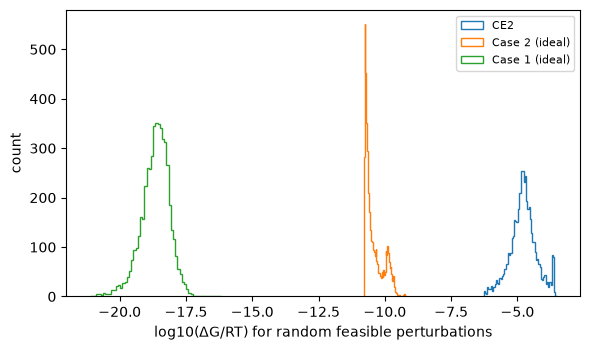

In [12]:
def gibbs_perturbations(system, res, pH=None, samples=5000, seed=1):
    """Directional derivative and exact ΔG/RT for random feasible reaction-extent steps (ideal activities)."""
    fixed = {"H+": -pH} if pH is not None else {}
    names = [sp.name for sp in system.species if sp.name not in fixed]
    solid = np.array([system[n].is_solid for n in names])
    N = np.array([[r.stoich.get(system[n], 0.0) for r in system.reactions] for n in names])
    logK = np.array([r.logK - sum(c * fixed[sp.name] for sp, c in r.stoich.items() if sp.name in fixed)
                     for r in system.reactions])
    mu0, *_ = np.linalg.lstsq(N.T, -LN10 * logK, rcond=None)
    x = np.array([res.molality[n] if n in res.molality else res.solids[n] for n in names])
    grad = np.where(solid, mu0, mu0 + np.log(np.where(solid, 1.0, x)))   # dG/dx at the computed state

    rng, first, total = np.random.default_rng(seed), [], []
    absent = solid & (x <= 0)
    aq = ~solid
    while len(total) < samples:
        d = N @ rng.normal(size=N.shape[1])
        if np.any(d[absent] < 0):
            if np.all(d[absent] <= 0):
                d = -d
            else:
                continue
        movable = (~absent) & (d != 0)
        t = 0.1 / np.max(np.abs(d[movable]) / x[movable])   # change no amount by more than 10%
        delta = t * d
        # exact, cancellation-free: G(x+δ) - G(x) = ∇G·δ + Σ_aq [(m+δ) log1p(δ/m) - δ]
        lin = grad @ delta
        curv = np.sum((x[aq] + delta[aq]) * np.log1p(delta[aq] / x[aq]) - delta[aq])
        first.append(lin / t)
        total.append(lin + curv)
    return np.array(first), np.array(total)

fig, ax = plt.subplots(figsize=(6, 3.6))
for label, (system, res, pH) in {
    "CE2": (systems["CE2"][0], ce["CE2"], None),
    "Case 2 (ideal)": (minteq_system(CASES["Case 2"]), checks[("Case 2", "ideal")][0], 7.0),
    "Case 1 (ideal)": (minteq_system(CASES["Case 1"]), checks[("Case 1", "ideal")][0], 5.0),
}.items():
    slope, dG = gibbs_perturbations(system, res, pH)
    print(f"{label:16s} {len(dG)} feasible directions: min directional derivative = {slope.min():+.1e}, "
          f"min ΔG/RT = {dG.min():.2e}, fraction with ΔG > 0: {np.mean(dG > 0):.4f}")
    ax.hist(np.log10(dG[dG > 0]), bins=60, histtype="step", label=label)
ax.set(xlabel="log10(ΔG/RT) for random feasible perturbations", ylabel="count")
ax.legend(fontsize=8)
plt.tight_layout()

**Result.** For all 5000 directions in each system, $\Delta G > 0$ (fraction = 1.0000).

- **Directional derivatives.** The smallest is +1.8 × 10⁻⁴ (CE2), −1.2 × 10⁻¹³ (Case 2; zero to round-off) and +6.5 × 10⁻³ (Case 1). Positive minima mean every feasible direction moves toward an undersaturated solid or away from mass action at first order.
- **Histogram.** The spread of $\Delta G$ between systems has nothing to do with correctness. Each step is capped so that no amount changes by more than 10%, and trace species (down to about 10⁻¹⁵ mol/kgw in Case 1) force very small steps.

## Summary

For every example in the paper and every counterexample:

- **E1:** the returned state satisfies conservation, mass action and solid complementarity to machine precision (every checker residual is 3 × 10⁻¹² or smaller). This was checked from the reaction data and formulas alone, with activity coefficients recomputed from scratch.
- **E2:** the phase assemblages match PHREEQC exactly. Amounts agree to 5 × 10⁻⁵ (ideal) and 5 × 10⁻⁴ (activity-corrected), and SI to 5 × 10⁻⁴. These gaps are the size of the known model differences, such as water activity and Debye–Hückel versus Davies.
- **E3:** complementarity homotopy, Gibbs minimization and exhaustive enumeration give the same state. Where enumeration finds more than one assemblage within tolerance (Case 3), the lowest-$G$ one is that same state.
- **E4:** adding polymorphs or inert phases, or rescaling a reaction, leaves the state unchanged. The SI² objective's value at that same state changes with these choices, so minimizing it cannot give a unique equilibrium.
- **E5:** none of the 5000 random feasible reaction-extent perturbations per system lowers the Gibbs energy. The directional derivatives are nonnegative to within round-off, about 10⁻¹³.

**Using this on your own problems.** `verify` and `gibbs_perturbations` work on any `System`, so you can reuse them. Every result also carries `res.residuals` and `res.converged`; see [`docs/validation.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/validation.md).

## Next steps

- [`03-databases-and-your-own-data.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/03-databases-and-your-own-data.ipynb): load full PHREEQC databases instead of hand-built case files.
- [`04-fitting-thermodynamic-data.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/04-fitting-thermodynamic-data.ipynb): estimate $\log K$ values from data.
- [`docs/validation.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/validation.md): the full PHREEQC comparison table, covering Truesdell–Jones, Pitzer, LLNL, SIT, exchange, surfaces and gases.
- [`docs/concepts.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/concepts.md): the equations, methods and conventions.

## References

- Laliwala, C.A., Amusat, O.O., and Torres, A.I. (2025). An optimization-based law of mass action precipitation/dissolution model. *Systems and Control Transactions* 4, 2140–2145. [doi:10.69997/sct.132742](https://doi.org/10.69997/sct.132742)
- Parkhurst, D.L., and Appelo, C.A.J. (2013). Description of input and examples for PHREEQC version 3. USGS Techniques and Methods 6-A43. [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)
- Allison, J.D., Brown, D.S., and Novo-Gradac, K.J. (1991). MINTEQA2/PRODEFA2 version 3.0 user's manual. EPA/600/3-91/021. [OSTI 5673069](https://www.osti.gov/biblio/5673069)
- Davies, C.W. (1938). The extent of dissociation of salts in water. Part VIII. *J. Chem. Soc.*, 2093. [doi:10.1039/JR9380002093](https://doi.org/10.1039/JR9380002093)
- Truesdell, A.H., and Jones, B.F. (1974). WATEQ, a computer program for calculating chemical equilibria of natural waters. *J. Res. U.S. Geol. Survey* 2, 233–248. [USGS](https://pubs.usgs.gov/publication/70232379)
- Fischer, A. (1992). A special Newton-type optimization method. *Optimization* 24, 269–284. [doi:10.1080/02331939208843795](https://doi.org/10.1080/02331939208843795)
- Kanzow, C. (1996). Some noninterior continuation methods for linear complementarity problems. *SIAM J. Matrix Anal. Appl.* 17, 851–868. [doi:10.1137/S0895479894273134](https://doi.org/10.1137/S0895479894273134)
- Smith, W.R., and Missen, R.W. (1982). *Chemical Reaction Equilibrium Analysis: Theory and Algorithms.* Wiley.

The full bibliography is in [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).